In [3]:
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
    AdaBoostRegressor, GradientBoostingRegressor,
    HistGradientBoostingRegressor, VotingRegressor, StackingRegressor
)

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

import warnings
warnings.filterwarnings("ignore")

## Data Cleaning

In [4]:
df = pd.read_csv(r"D:\Material of Machine Learning Course\my_projects\Project Apartments Prices Dataset\Apartments Prices Dataset.csv")

In [5]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [6]:
df.shape

(5578, 11)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   price           5578 non-null   str  
 1   area_sqm        5578 non-null   str  
 2   rooms           5578 non-null   str  
 3   bathrooms       5578 non-null   str  
 4   floor_level     5578 non-null   str  
 5   year_built      5578 non-null   int64
 6   seller_type     5578 non-null   str  
 7   view            5578 non-null   str  
 8   price_per_sqm   5578 non-null   str  
 9   payment_method  5578 non-null   str  
 10  finishing_type  5578 non-null   str  
dtypes: int64(1), str(10)
memory usage: 479.5 KB


In [8]:
df.isnull().sum()

price             0
area_sqm          0
rooms             0
bathrooms         0
floor_level       0
year_built        0
seller_type       0
view              0
price_per_sqm     0
payment_method    0
finishing_type    0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(1489)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.duplicated().sum()

np.int64(0)

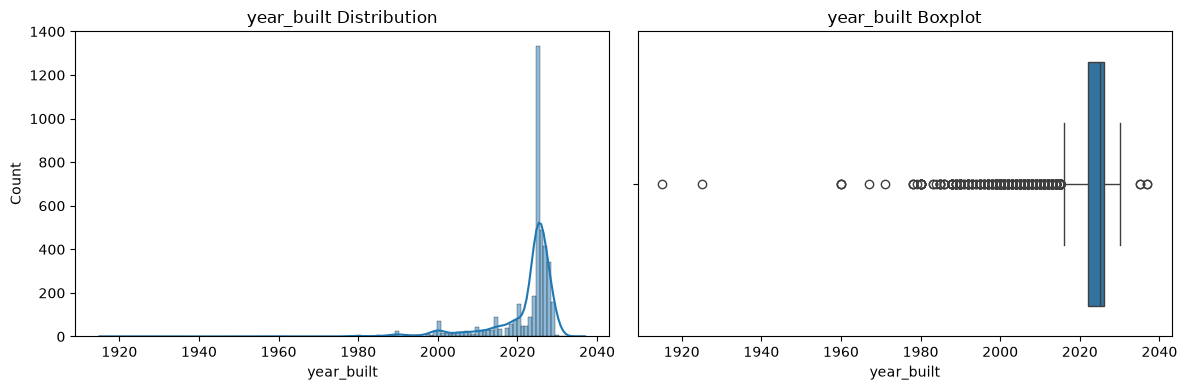

In [12]:
def plot_numerical_features(data):
    numerical_cols = data.select_dtypes(include="number").columns

    for col in numerical_cols:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        sns.histplot(data=data, x=col, kde=True, ax=axes[0])
        axes[0].set_title(f"{col} Distribution")
        sns.boxplot(data=data, x=col, ax=axes[1])
        axes[1].set_title(f"{col} Boxplot")
        plt.tight_layout()
        plt.show()

plot_numerical_features(df)

## Exploratory Data Analysis (EDA)

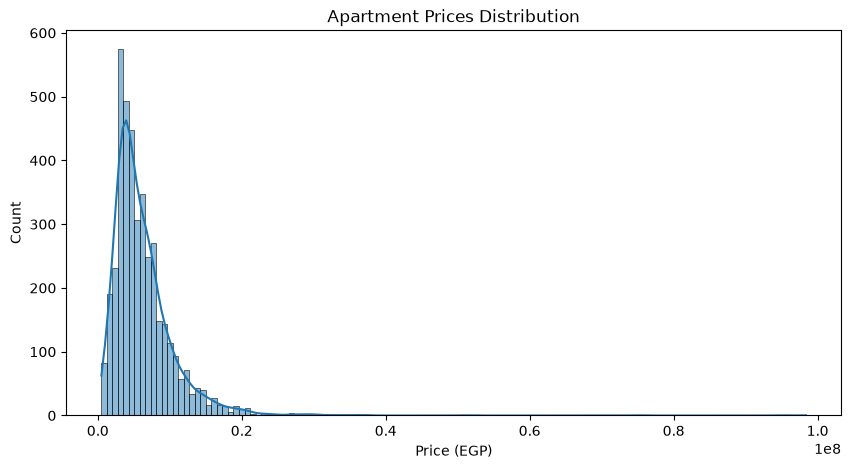

In [13]:
# Target distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["price"].astype(str).str.replace(r"[^0-9.]", "", regex=True).astype(float), kde=True)
plt.title("Apartment Prices Distribution")
plt.xlabel("Price (EGP)")
plt.show()

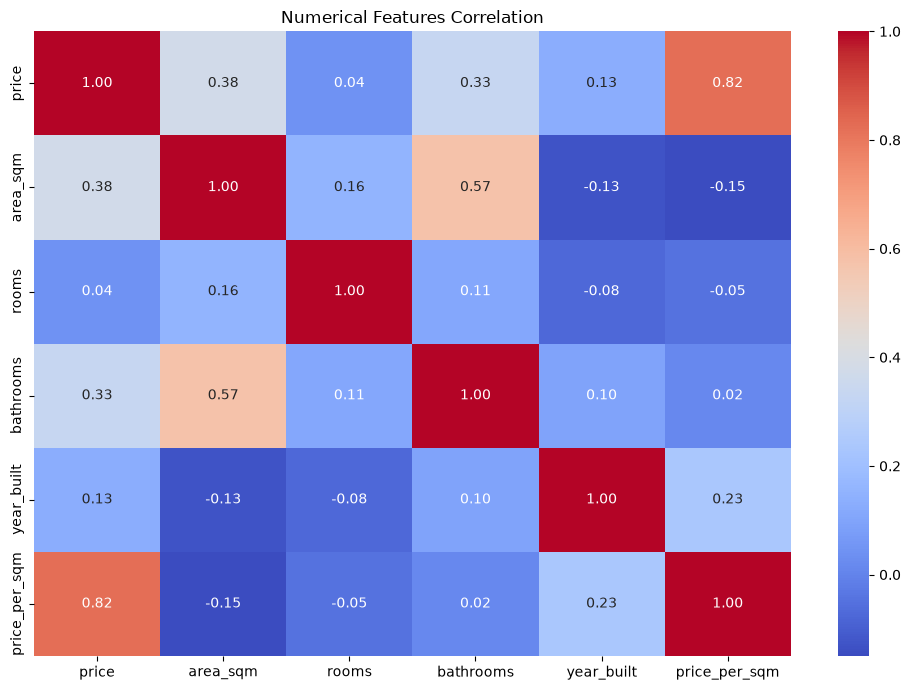

In [14]:
# Correlation after converting the numeric-looking columns
eda_df = df.copy()
for col in ["price", "area_sqm", "rooms", "bathrooms", "price_per_sqm"]:
    eda_df[col] = pd.to_numeric(
        eda_df[col].astype(str).str.replace(r"[^0-9.]", "", regex=True),
        errors="coerce"
    )
plt.figure(figsize=(10, 7))
sns.heatmap(eda_df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Features Correlation")
plt.tight_layout()
plt.show()

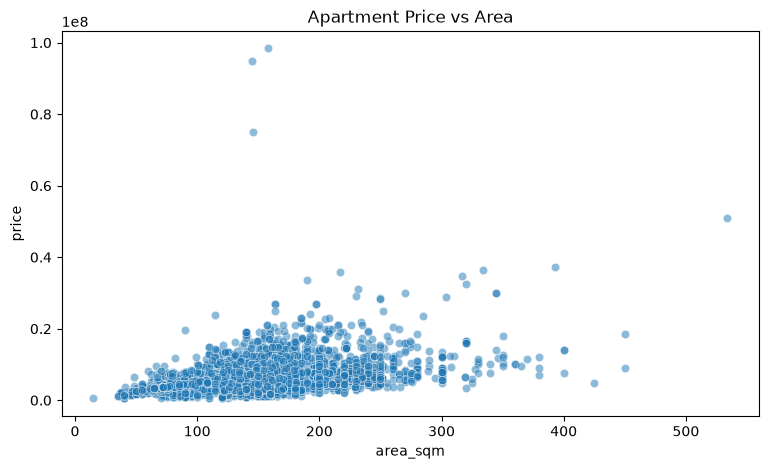

In [15]:
# Price against apartment area
plt.figure(figsize=(9, 5))
sns.scatterplot(data=eda_df, x="area_sqm", y="price", alpha=0.5)
plt.title("Apartment Price vs Area")
plt.show()

## Prepare Input and Output Features

In [ ]:
data = df.copy()

def extract_number(series):
    return pd.to_numeric(
        series.astype(str).str.replace(",", "", regex=False).str.extract(r"([-+]?[0-9]*\.?[0-9]+)")[0],
        errors="coerce"
    )

data["price"] = extract_number(data["price"])
data["area_sqm"] = extract_number(data["area_sqm"])
data["rooms"] = extract_number(data["rooms"])
data["bathrooms"] = extract_number(data["bathrooms"])
data["price_per_sqm"] = extract_number(data["price_per_sqm"])

data["floor_level"] = data["floor_level"].replace({"Ground": "0"})
data["floor_level"] = pd.to_numeric(data["floor_level"], errors="coerce")

data = data.dropna(subset=["price"]).copy()

numeric_cols = data.select_dtypes(include=np.number).columns
categorical_cols = data.select_dtypes(exclude=np.number).columns

for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

for col in categorical_cols:
    if data[col].isna().any():
        data[col] = data[col].fillna(data[col].mode()[0])

data.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,2163000,120,2,3,3,2025,Developer,Main Street,18025.0,Installments,Semi Finished
1,3250000,162,3,2,6,2024,Developer,Main Street,20062.0,Cash or Installments,Semi Finished
2,2650000,122,3,1,4,2024,Developer,Main Street,21721.0,Cash or Installments,Semi Finished
3,12720000,212,4,3,13,2027,Broker,Club,60000.0,Cash or Installments,Extra Super Lux
4,5898000,135,2,1,6,2025,Developer,Lake,43689.0,Cash or Installments,Super Lux


In [ ]:
X = data.drop(["price", "price_per_sqm"], axis=1)
y = data["price"]

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (4089, 9)
y shape: (4089,)


,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,payment_method,finishing_type
0,120,2,3,3,2025,Developer,Main Street,Installments,Semi Finished
1,162,3,2,6,2024,Developer,Main Street,Cash or Installments,Semi Finished
2,122,3,1,4,2024,Developer,Main Street,Cash or Installments,Semi Finished
3,212,4,3,13,2027,Broker,Club,Cash or Installments,Extra Super Lux
4,135,2,1,6,2025,Developer,Lake,Cash or Installments,Super Lux


## Encode Categorical Features

In [ ]:
X = pd.get_dummies(X, drop_first=False, dtype=float)

X = X.astype(float)

print("Features after encoding:", X.shape[1])
X.head()

Features after encoding: 33


,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type_Broker,seller_type_Cash,seller_type_Cash or Installments,seller_type_Compound Developer,seller_type_Developer,...,view_Sea View,view_Side Street,payment_method_Cash,payment_method_Cash or Installments,payment_method_Installments,finishing_type_Extra Super Lux,finishing_type_Lux,finishing_type_Semi Finished,finishing_type_Super Lux,finishing_type_Without Finish
0,120.0,2.0,3.0,3.0,2025.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,162.0,3.0,2.0,6.0,2024.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,122.0,3.0,1.0,4.0,2024.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,212.0,4.0,3.0,13.0,2027.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
4,135.0,2.0,1.0,6.0,2025.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


## Split into Train and Test Sets

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)

In [21]:
print("X_train =", X_train.shape, " y_train =", y_train.shape)
print("X_test  =", X_test.shape, " y_test  =", y_test.shape)

X_train = (3271, 33)  y_train = (3271,)
X_test  = (818, 33)  y_test  = (818,)


## Feature Scaling

In [22]:
my_scaler = MinMaxScaler(feature_range=(0, 1))
X_train = my_scaler.fit_transform(X_train)
X_test = my_scaler.transform(X_test)

## Regression Models

In [23]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5, metric="minkowski", p=1),
    "SVM": SVR(kernel="linear", C=100, gamma=1),
    "Decision Tree": DecisionTreeRegressor(criterion="squared_error", max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=50, criterion="squared_error", max_depth=10, random_state=42),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion="squared_error", max_depth=10), n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

## Regression Metrics

In [24]:
def regression_metrics(model, X_values, y_actual):
    y_pred = model.predict(X_values)
    mae = mean_absolute_error(y_actual, y_pred)
    mse = mean_squared_error(y_actual, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_actual, y_pred)
    return mae, mse, rmse, r2

## Train and Evaluate All Models

  0%|          | 0/15 [00:00<?, ?it/s]

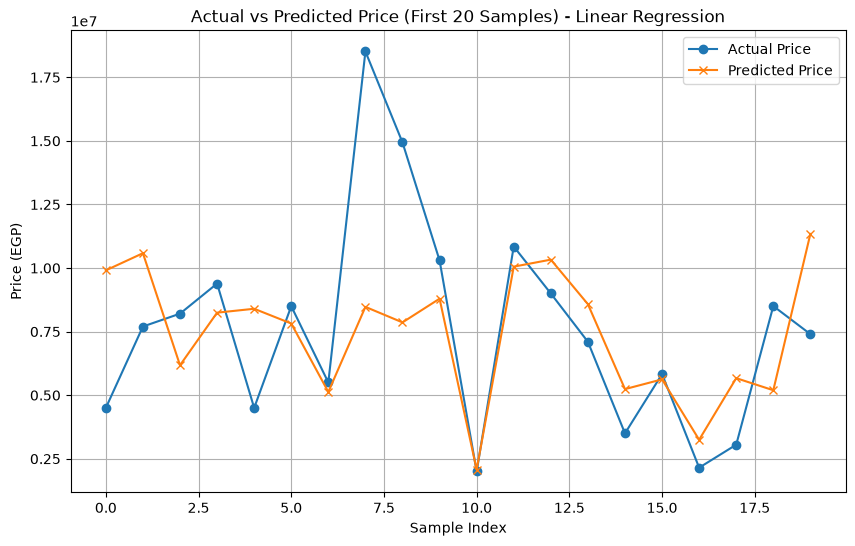

  7%|▋         | 1/15 [00:00<00:07,  1.75it/s]

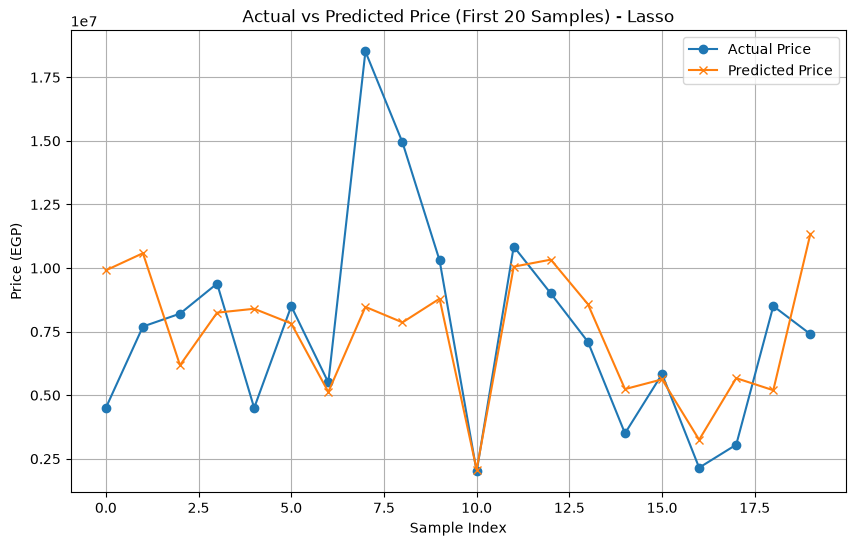

 13%|█▎        | 2/15 [00:01<00:06,  2.05it/s]

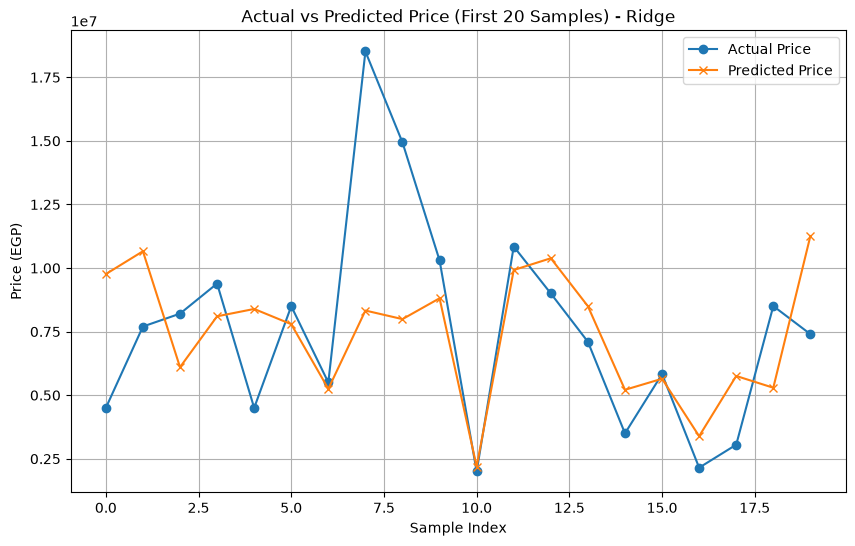

 20%|██        | 3/15 [00:01<00:05,  2.00it/s]

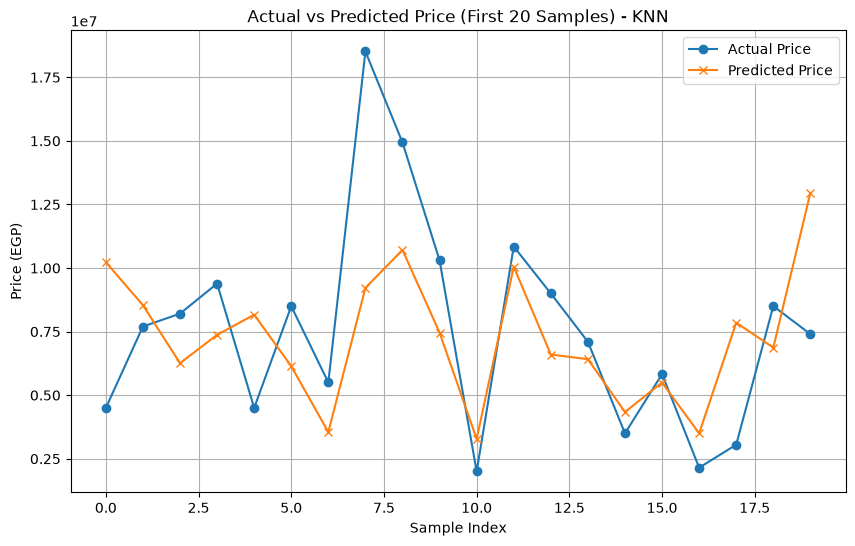

 27%|██▋       | 4/15 [00:07<00:27,  2.48s/it]

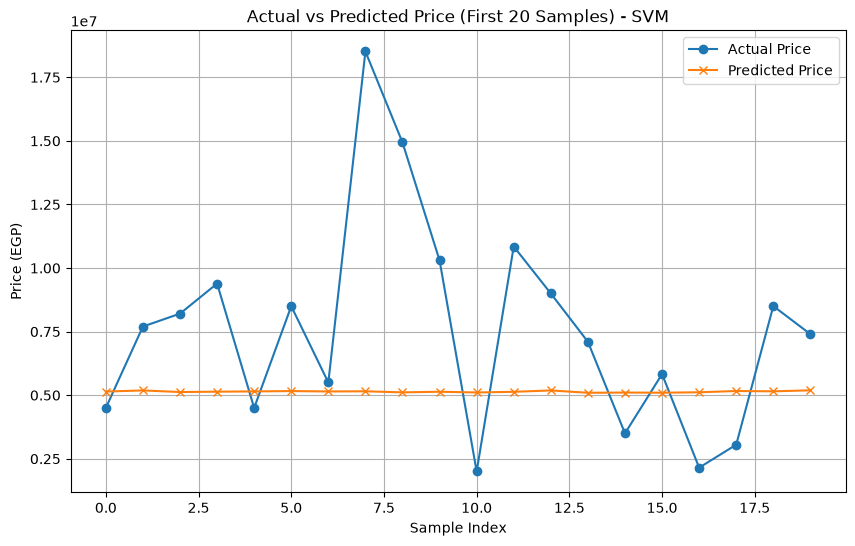

 33%|███▎      | 5/15 [00:07<00:19,  1.93s/it]

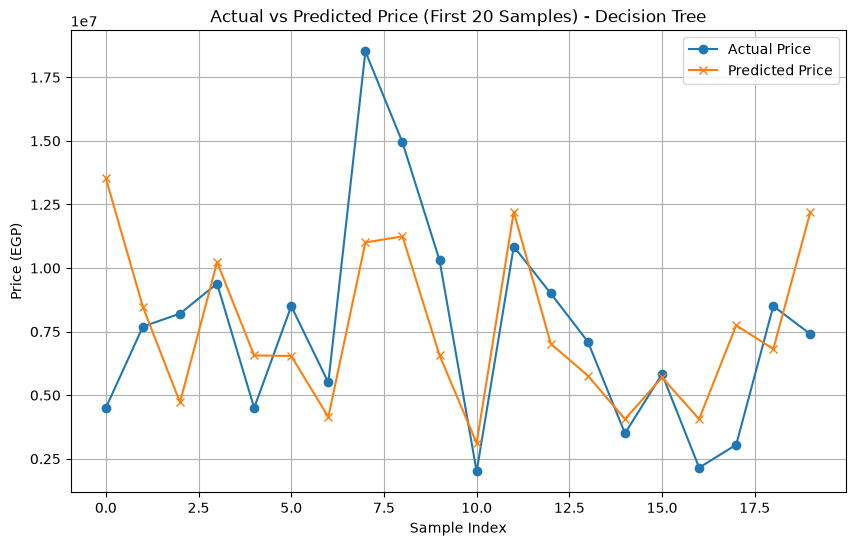

 40%|████      | 6/15 [00:08<00:12,  1.37s/it]

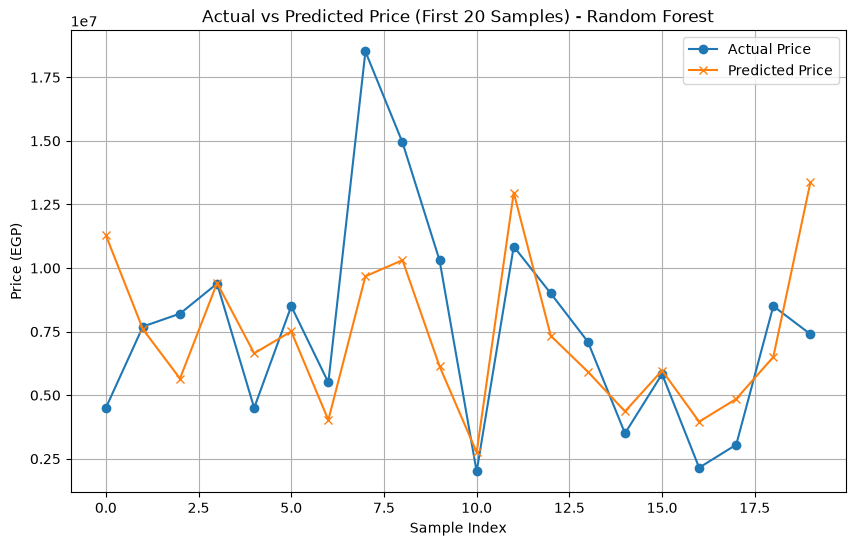

 47%|████▋     | 7/15 [00:09<00:10,  1.27s/it]

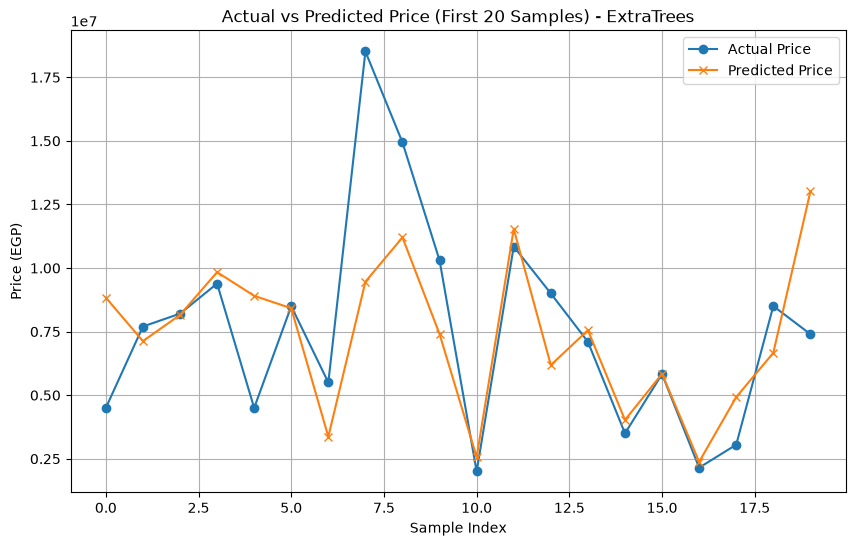

 53%|█████▎    | 8/15 [00:13<00:15,  2.23s/it]

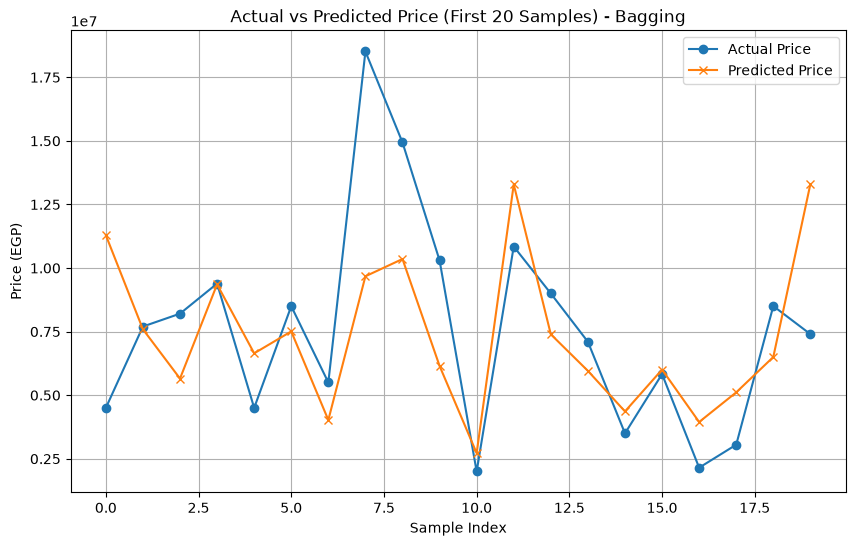

 60%|██████    | 9/15 [00:15<00:12,  2.01s/it]

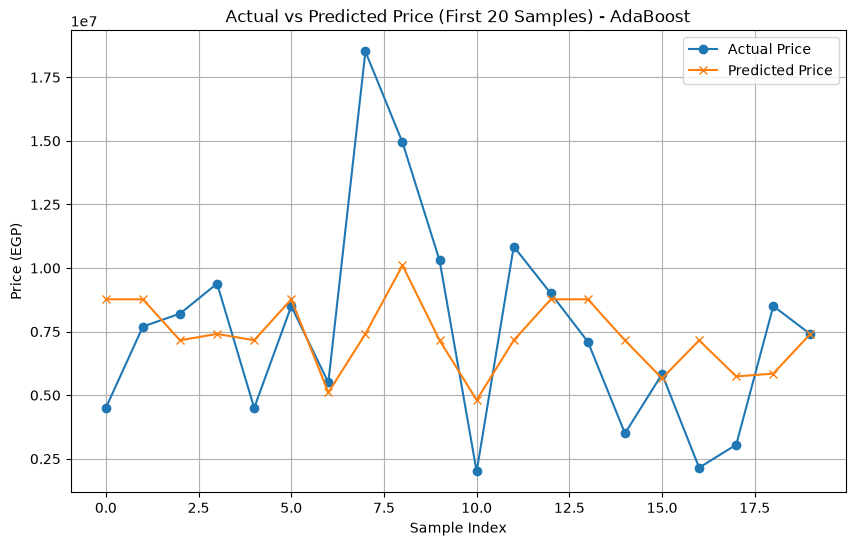

 67%|██████▋   | 10/15 [00:15<00:07,  1.52s/it]

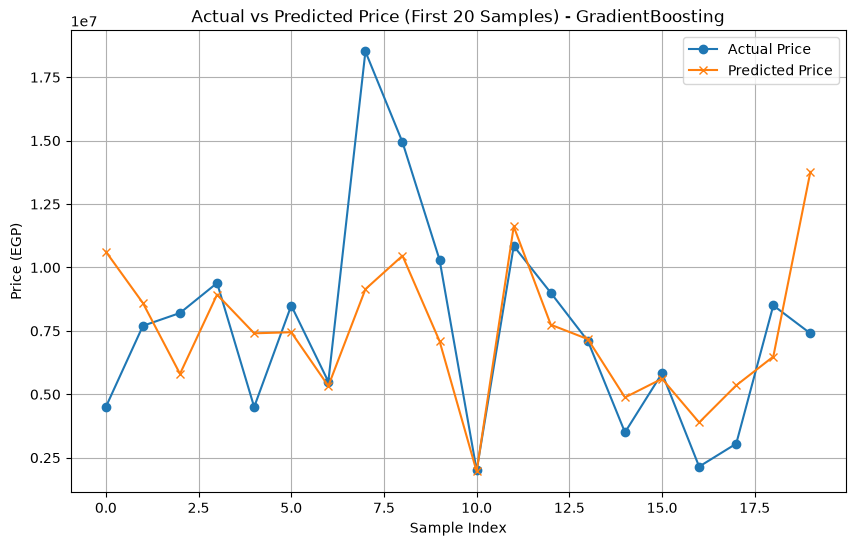

 73%|███████▎  | 11/15 [00:16<00:05,  1.48s/it]

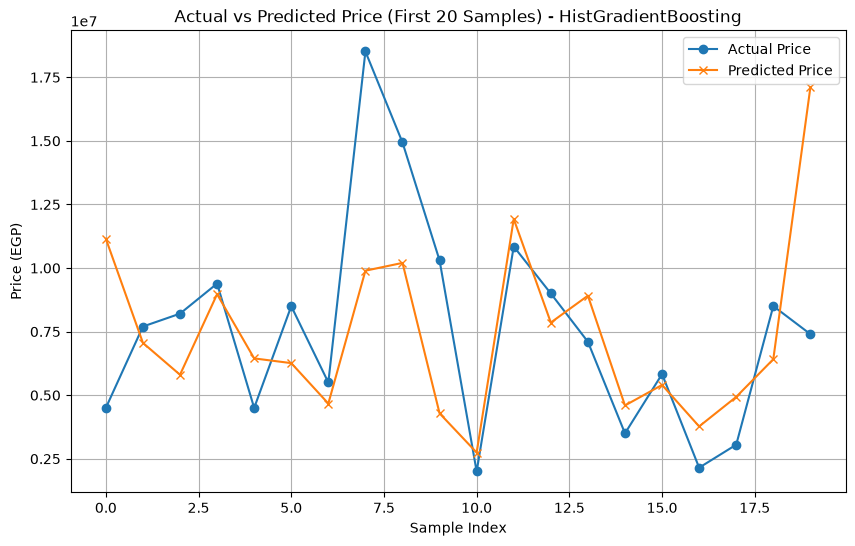

 80%|████████  | 12/15 [00:18<00:04,  1.58s/it]

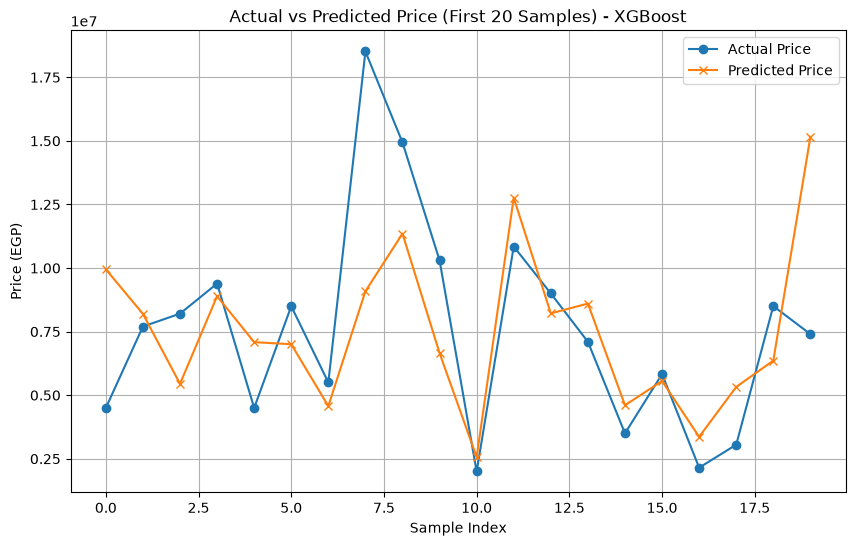

 87%|████████▋ | 13/15 [00:19<00:02,  1.44s/it]

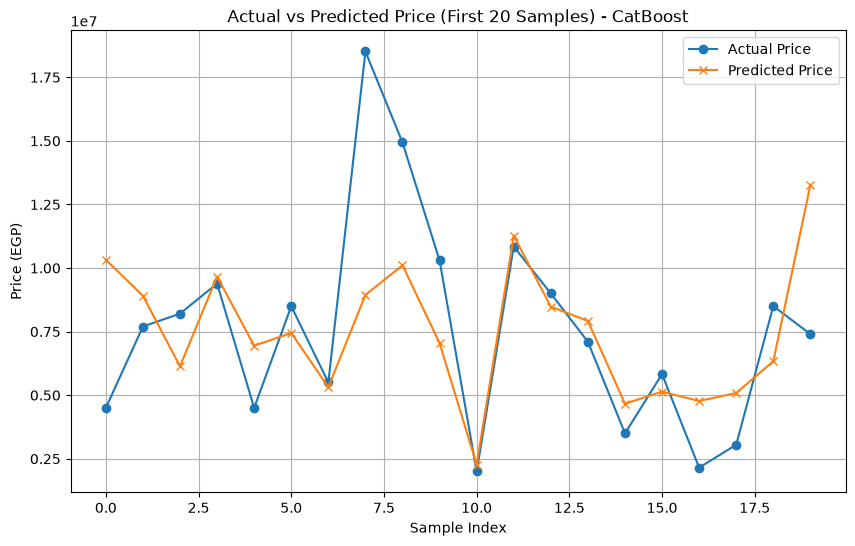

 93%|█████████▎| 14/15 [00:20<00:01,  1.34s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005939 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 323
[LightGBM] [Info] Number of data points in the train set: 3271, number of used features: 26
[LightGBM] [Info] Start training from score 6280182.378783


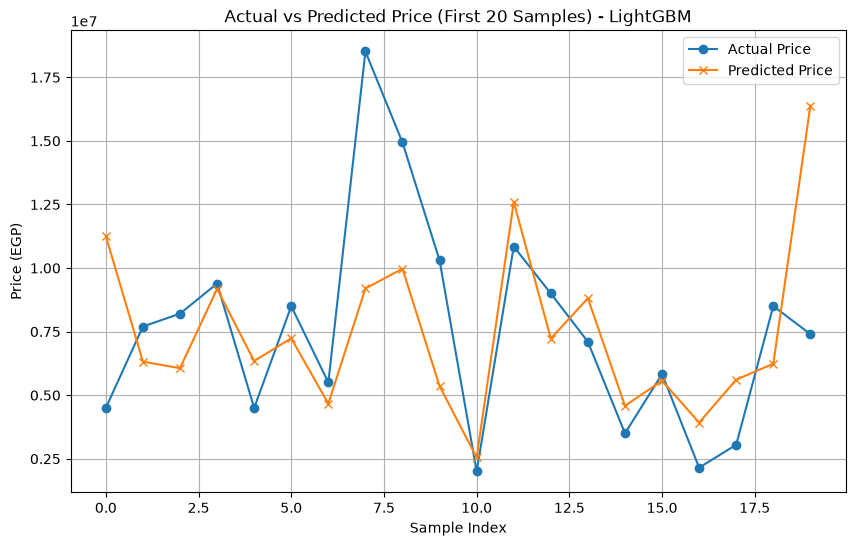

100%|██████████| 15/15 [00:21<00:00,  1.44s/it]


In [25]:
errors = {}
trained_models = {}

for model_name, model in tqdm(models.items()):
    model.fit(X_train, y_train)
    trained_models[model_name] = model

    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R_Train,
        "R2 Test": R_Test
    }

    # Actual vs Predicted for the first 20 test samples
    sample_count = min(20, len(y_test))
    y_test_plot = y_test.iloc[:sample_count].values
    y_pred_plot = model.predict(X_test[:sample_count])

    plt.figure(figsize=(10, 6))
    plt.plot(range(sample_count), y_test_plot, label="Actual Price", marker="o")
    plt.plot(range(sample_count), y_pred_plot, label="Predicted Price", marker="x")
    plt.xlabel("Sample Index")
    plt.ylabel("Price (EGP)")
    plt.title(f"Actual vs Predicted Price (First {sample_count} Samples) - {model_name}")
    plt.legend()
    plt.grid()
    plt.show()

## Voting Regression

In [ ]:
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

voting_model = VotingRegressor(estimators=[
    ("lr", clf1), ("rf", clf2), ("dt", clf3)
])

weighted_voting_model = VotingRegressor(
    estimators=[
        ("lr", clf1), ("rf", clf2), ("dt", clf3)
    ],
    weights=[2, 1, 2]
)

voting_model.fit(X_train, y_train)
weighted_voting_model.fit(X_train, y_train)

for model_name, model in [
    ("Voting", voting_model),
    ("Weighted Voting", weighted_voting_model)
]:
    MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train,
        "R2 Test": R2_Test
    }

trained_models["Voting"] = voting_model
trained_models["Weighted Voting"] = weighted_voting_model

## Stacking Regression

In [27]:
regressors = [
    ("rf", RandomForestRegressor(n_estimators=50, random_state=42)),
    ("gb", GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ("cat", CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0, random_state=42)),
    ("lgb", LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

meta_regressor = XGBRegressor(
    n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0
)

stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)

stacking_regressor.fit(X_train, y_train)

MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)

errors["Stacking"] = {
    "MAE Train": MAE_Train,
    "MAE Test": MAE_Test,
    "MSE Train": MSE_Train,
    "MSE Test": MSE_Test,
    "RMSE Train": RMSE_Train,
    "RMSE Test": RMSE_Test,
    "R2 Train": R2_Train,
    "R2 Test": R2_Test
}
trained_models["Stacking"] = stacking_regressor

## Compare All Models

In [28]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test", ascending=False)
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
CatBoost,1.914356e+06,1.923042e+06,1.149234e+13,8.126834e+12,3.390036e+06,2.850760e+06,0.508155,0.494814
LightGBM,1.529471e+06,1.912121e+06,8.267281e+12,8.209239e+12,2.875288e+06,2.865177e+06,0.646180,0.489691
GradientBoosting,1.928854e+06,1.956526e+06,1.226019e+13,8.215139e+12,3.501455e+06,2.866206e+06,0.475293,0.489324
HistGradientBoosting,1.525931e+06,1.891963e+06,8.172919e+12,8.274527e+12,2.858832e+06,2.876548e+06,0.650218,0.485633
XGBoost,1.409094e+06,1.893476e+06,6.003330e+12,8.964702e+12,2.450169e+06,2.994111e+06,0.743072,0.442729
Bagging,1.437366e+06,1.880538e+06,5.967517e+12,9.222171e+12,2.442850e+06,3.036803e+06,0.744604,0.426725
Random Forest,1.434168e+06,1.878168e+06,5.951936e+12,9.367692e+12,2.439659e+06,3.060668e+06,0.745271,0.417679
ExtraTrees,6.813599e+04,1.750364e+06,1.310729e+12,9.744419e+12,1.144871e+06,3.121605e+06,0.943904,0.394260
Stacking,1.371313e+06,1.896574e+06,1.121390e+13,1.028479e+13,3.348717e+06,3.206990e+06,0.520071,0.360669
Ridge,2.290742e+06,2.249287e+06,1.653511e+13,1.044204e+13,4.066339e+06,3.231414e+06,0.292336,0.350894


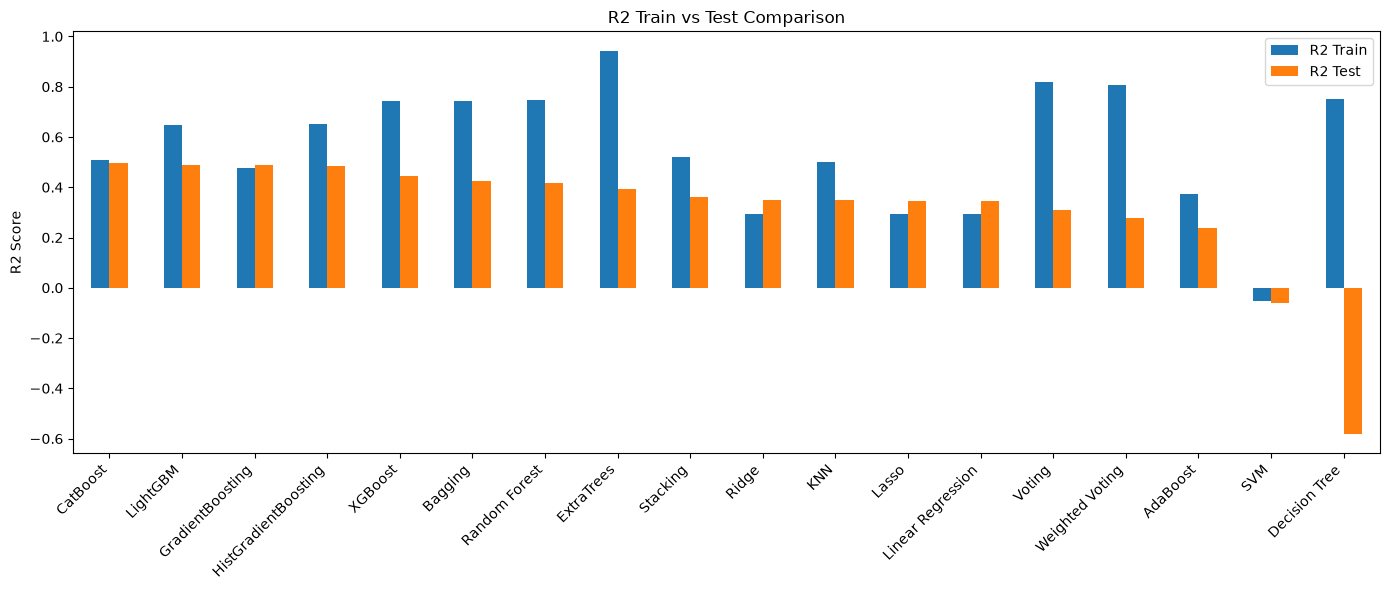

In [29]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(14, 6))
plt.title("R2 Train vs Test Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

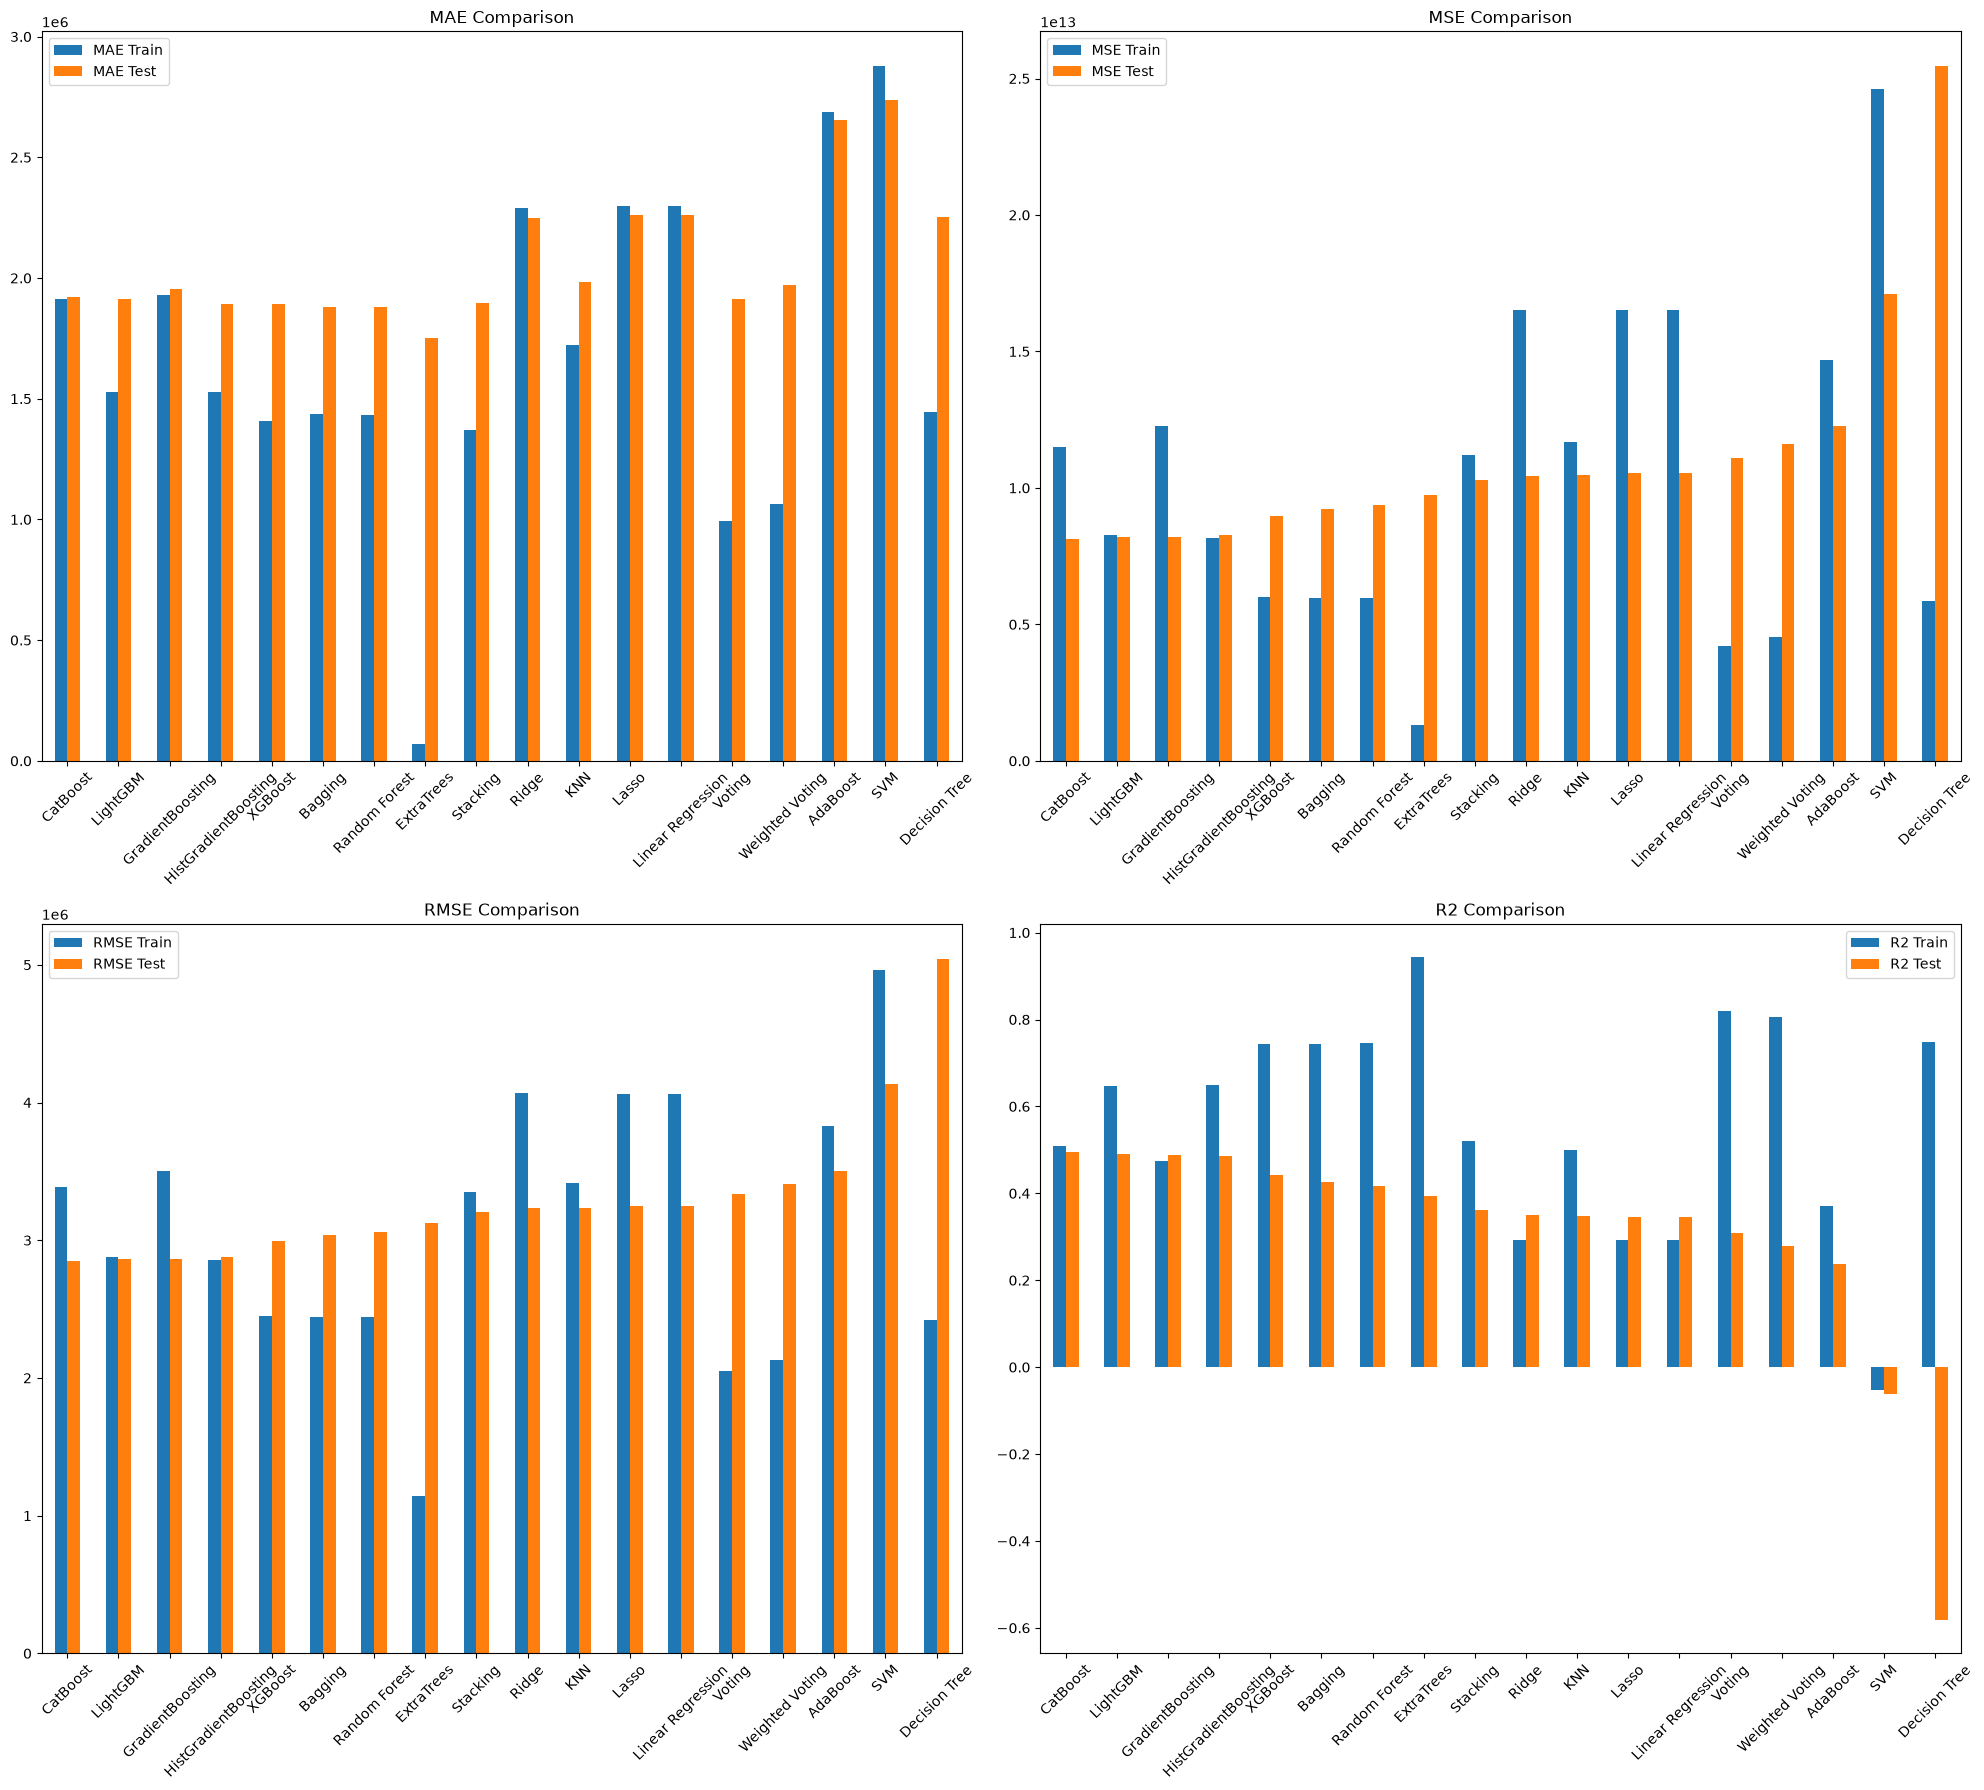

In [30]:
cols = [
    ["MAE Train", "MAE Test"],
    ["MSE Train", "MSE Test"],
    ["RMSE Train", "RMSE Test"],
    ["R2 Train", "R2 Test"]
]

fig = plt.figure(figsize=(20, 18))
for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i + 1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + " Comparison")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## Best Model

In [31]:
best_model_name = errors_df["R2 Test"].idxmax()
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print(errors_df.loc[best_model_name])

Best Model: CatBoost
MAE Train     1.914356e+06
MAE Test      1.923042e+06
MSE Train     1.149234e+13
MSE Test      8.126834e+12
RMSE Train    3.390036e+06
RMSE Test     2.850760e+06
R2 Train      5.081545e-01
R2 Test       4.948137e-01
Name: CatBoost, dtype: float64


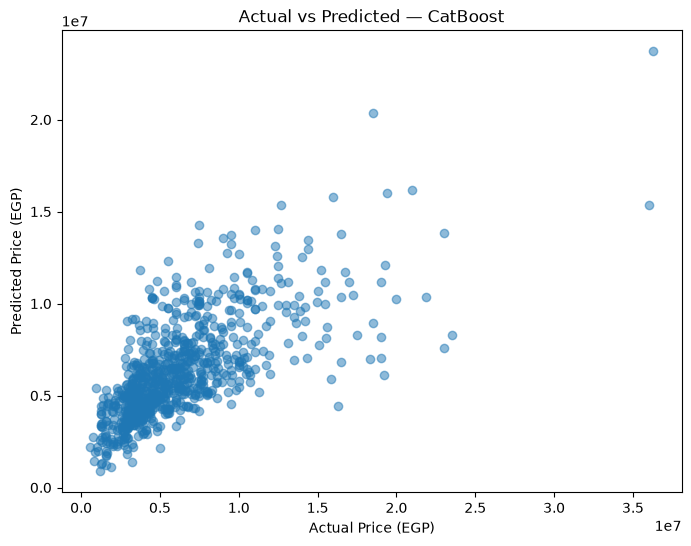

In [32]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions, alpha=0.5)
plt.xlabel("Actual Price (EGP)")
plt.ylabel("Predicted Price (EGP)")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.show()